# Gradient Descent & Modern Optimizers from Scratch 📉

Optimization is the beating heart of Machine Learning and Deep Learning. Its objective: **find the weights and biases that minimize a loss function.**

### The Core Update Rule:
$$\theta := \theta - \eta \cdot \nabla J(\theta)$$

* $\theta$: Parameter to optimize (weights $w$ or bias $b$).
* $\eta$ (eta): Learning rate (step size).
* $\nabla J(\theta)$: The gradient (direction of steepest increase).
* The **minus sign** ($-$) ensures we step in the *opposite* direction of the slope (downhill!).


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Plotting settings
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = [9, 5]
np.random.seed(42)


---
## Part 1: Gradient Descent in 1D (Visual Intuition)

Let's find the minimum of a simple 1D curve:
$$f(x) = x^2$$

Its derivative (slope) is:
$$f'(x) = 2x$$

* If we start at $x = 4$, slope $= 2(4) = 8$ (positive $\implies$ curve rises to the right).
* To go downhill, we step left: $x_{\text{new}} = x - \eta \cdot 8$.


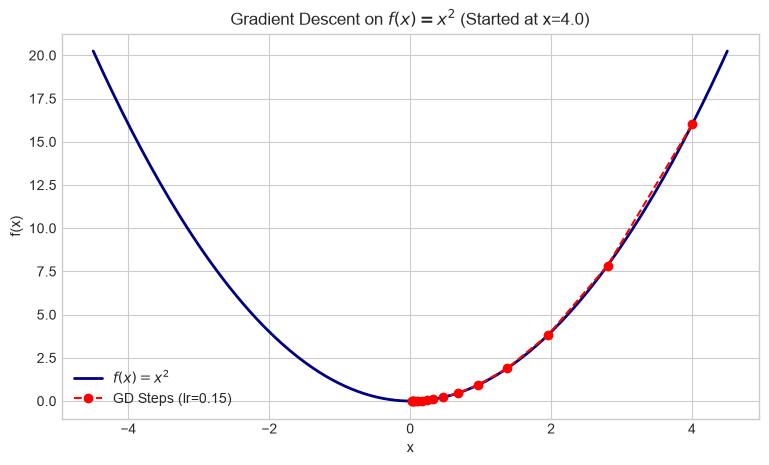

Started at: x = 4.00
Ended at:   x = 0.018990 after 15 steps (Target = 0.0)


In [2]:
def f(x):
    return x**2

def df(x):
    return 2 * x

def gradient_descent_1d(x_start, lr, n_steps):
    history = [x_start]
    x = x_start
    for _ in range(n_steps):
        grad = df(x)
        x = x - lr * grad
        history.append(x)
    return np.array(history)

# Run Gradient Descent
x_start = 4.0
lr = 0.15
steps = 15
history = gradient_descent_1d(x_start, lr, steps)

# Plot steps down the bowl
x_vals = np.linspace(-4.5, 4.5, 200)
plt.plot(x_vals, f(x_vals), label="$f(x) = x^2$", color='navy', lw=2)
plt.plot(history, f(history), 'ro--', label=f'GD Steps (lr={lr})', markersize=6)
plt.title(f"Gradient Descent on $f(x) = x^2$ (Started at x={x_start})")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.legend()
plt.show()

print(f"Started at: x = {x_start:.2f}")
print(f"Ended at:   x = {history[-1]:.6f} after {steps} steps (Target = 0.0)")


### Why the Learning Rate ($\eta$) Matters
* **Too Small ($\eta = 0.02$):** Takes tiny baby steps; slow to converge.
* **Just Right ($\eta = 0.15$):** Smoothly slides down to the minimum.
* **Too Large ($\eta = 1.05$):** Overshoots the valley, bounces higher and higher, and **diverges**!


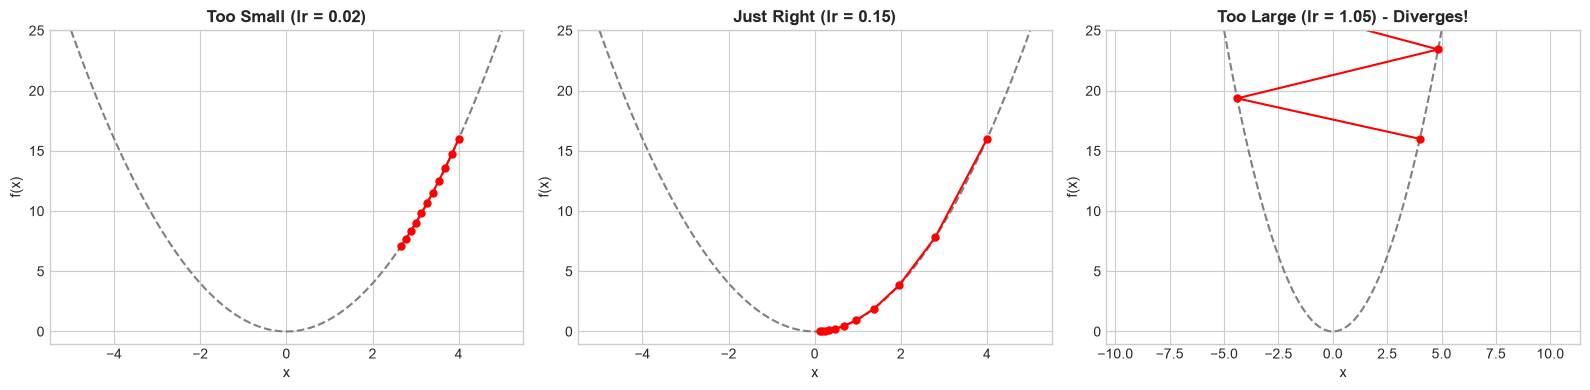

In [3]:
learning_rates = [0.02, 0.15, 1.05]
titles = ["Too Small (lr = 0.02)", "Just Right (lr = 0.15)", "Too Large (lr = 1.05) - Diverges!"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
x_vals = np.linspace(-5, 5, 200)

for ax, lr_val, title in zip(axes, learning_rates, titles):
    hist = gradient_descent_1d(x_start=4.0, lr=lr_val, n_steps=10)
    ax.plot(x_vals, f(x_vals), color='gray', linestyle='--')
    ax.plot(hist, f(hist), 'ro-', markersize=5)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel("x")
    ax.set_ylabel("f(x)")
    ax.set_ylim(-1, 25)

plt.tight_layout()
plt.show()


---
## Part 2: Gradient Descent for a Model (Linear Regression)

Now let's find the optimal **Weight ($w$)** and **Bias ($b$)** to fit a dataset.

### 1. Model:
$$\hat{y} = w x + b$$

### 2. Loss Function (Mean Squared Error - MSE):
$$J(w, b) = \frac{1}{m} \sum_{i=1}^m (\hat{y}^{(i)} - y^{(i)})^2$$

### 3. Gradients (How much error comes from $w$ and $b$):
$$\frac{\partial J}{\partial w} = \frac{2}{m} \sum_{i=1}^m (\hat{y}^{(i)} - y^{(i)}) \cdot x^{(i)}$$
$$\frac{\partial J}{\partial b} = \frac{2}{m} \sum_{i=1}^m (\hat{y}^{(i)} - y^{(i)})$$


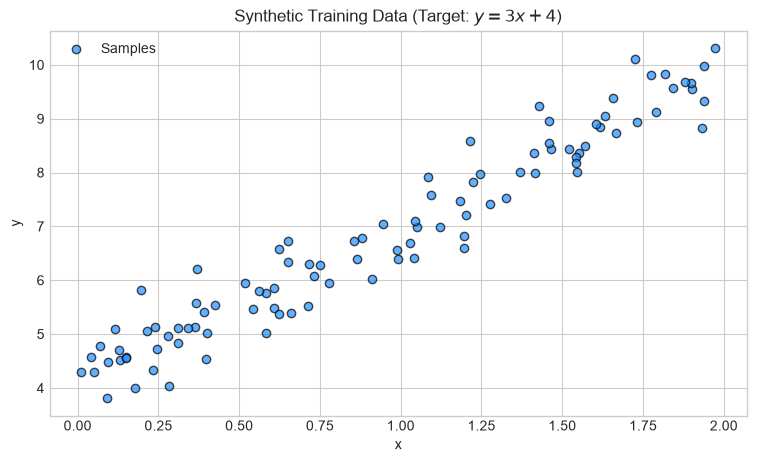

In [4]:
# Synthetic training data: y = 3x + 4 + noise
m = 100
X = 2 * np.random.rand(m, 1)
true_w = 3.0
true_b = 4.0
y = true_w * X + true_b + np.random.randn(m, 1) * 0.5

plt.scatter(X, y, color='dodgerblue', alpha=0.7, edgecolors='k', label='Samples')
plt.title("Synthetic Training Data (Target: $y = 3x + 4$)")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()


In [5]:
# Initialize parameters randomly
w = np.random.randn(1)
b = np.random.randn(1)
lr = 0.1
epochs = 60

loss_history = []
w_history = [float(w[0])]
b_history = [float(b[0])]

# Training Loop: Forward -> Loss -> Gradients -> Update
for epoch in range(epochs):
    # 1. Forward Pass
    y_pred = w * X + b
    
    # 2. Loss Computation
    loss = np.mean((y_pred - y)**2)
    loss_history.append(loss)
    
    # 3. Gradients (Backprop)
    error = y_pred - y
    grad_w = (2 / m) * np.sum(error * X)
    grad_b = (2 / m) * np.sum(error)
    
    # 4. Gradient Descent Step
    w -= lr * grad_w
    b -= lr * grad_b
    
    w_history.append(float(w[0]))
    b_history.append(float(b[0]))

print(f"Learned Weight w: {w[0]:.4f} (True: {true_w})")
print(f"Learned Bias b:   {b[0]:.4f} (True: {true_b})")
print(f"Final MSE Loss:   {loss_history[-1]:.4f}")


Learned Weight w: 2.8924 (True: 3.0)
Learned Bias b:   4.0992 (True: 4.0)
Final MSE Loss:   0.2017


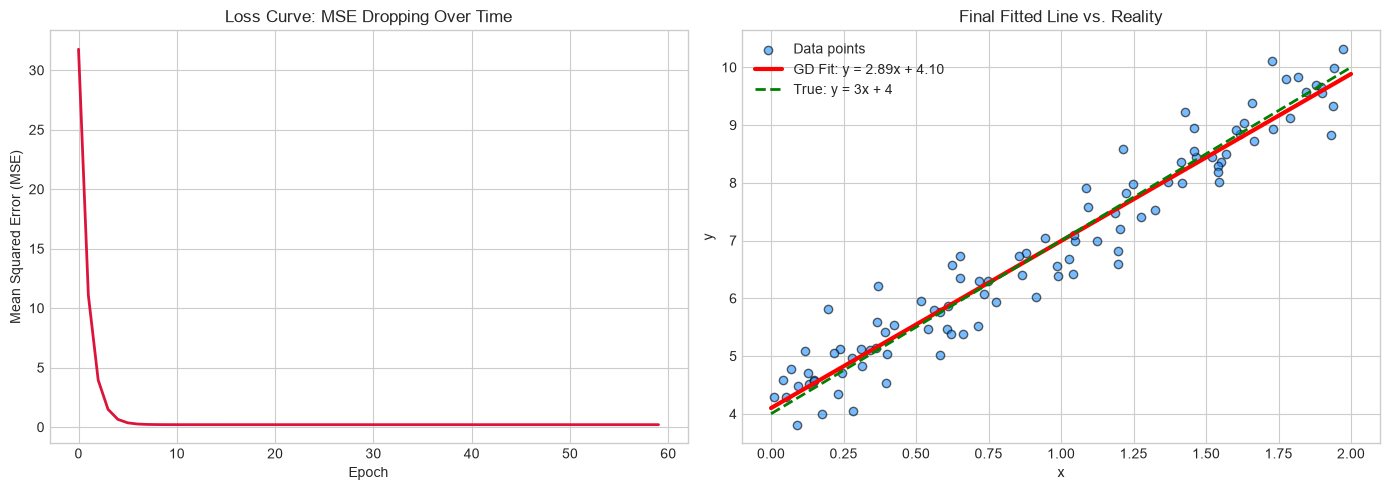

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Loss dropping over epochs
ax1.plot(loss_history, color='crimson', lw=2)
ax1.set_title("Loss Curve: MSE Dropping Over Time")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Mean Squared Error (MSE)")

# Plot 2: Fitted line vs actual data
ax2.scatter(X, y, color='dodgerblue', alpha=0.6, edgecolors='k', label='Data points')
x_line = np.array([[0], [2]])
ax2.plot(x_line, w * x_line + b, color='red', lw=3, label=f'GD Fit: y = {w[0]:.2f}x + {b[0]:.2f}')
ax2.plot(x_line, true_w * x_line + true_b, color='green', linestyle='--', lw=2, label='True: y = 3x + 4')
ax2.set_title("Final Fitted Line vs. Reality")
ax2.set_xlabel("x")
ax2.set_ylabel("y")
ax2.legend()

plt.tight_layout()
plt.show()


---
## Part 3: Batch GD vs. Stochastic GD (SGD)

* **Batch Gradient Descent:** Uses all $m = 100$ samples every step $\implies$ smooth, direct path to minimum.
* **Stochastic Gradient Descent (SGD):** Uses **1 random sample at a time** $\implies$ noisy, zig-zags around, but takes steps much faster and handles huge datasets.


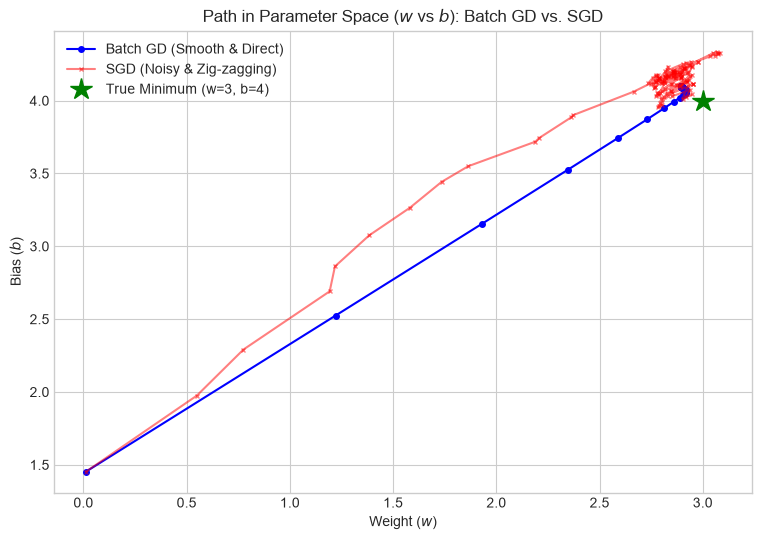

In [7]:
# Run SGD from the exact same starting point
w_sgd = np.array([w_history[0]])
b_sgd = np.array([b_history[0]])
w_sgd_history = [float(w_sgd[0])]
b_sgd_history = [float(b_sgd[0])]

n_sgd_steps = 150
lr_sgd = 0.05

for step in range(n_sgd_steps):
    idx = np.random.randint(m)
    xi = X[idx:idx+1]
    yi = y[idx:idx+1]
    
    y_pred_i = w_sgd * xi + b_sgd
    error_i = y_pred_i - yi
    
    grad_w_i = 2 * error_i * xi
    grad_b_i = 2 * error_i
    
    w_sgd -= lr_sgd * grad_w_i.squeeze()
    b_sgd -= lr_sgd * grad_b_i.squeeze()
    
    w_sgd_history.append(float(w_sgd[0]))
    b_sgd_history.append(float(b_sgd[0]))

# Visual comparison in (w, b) space
plt.figure(figsize=(9, 6))
plt.plot(w_history, b_history, 'b-o', markersize=4, label='Batch GD (Smooth & Direct)')
plt.plot(w_sgd_history, b_sgd_history, 'r-x', markersize=3, alpha=0.5, label='SGD (Noisy & Zig-zagging)')
plt.plot(true_w, true_b, 'g*', markersize=16, label='True Minimum (w=3, b=4)')

plt.title("Path in Parameter Space ($w$ vs $b$): Batch GD vs. SGD")
plt.xlabel("Weight ($w$)")
plt.ylabel("Bias ($b$)")
plt.legend()
plt.show()


---
## Part 4: Modern Optimizers Showdown (The Ravine Challenge) 🏔️

In deep learning, loss landscapes are rarely neat circles. They often have **steep ravines**:
* Extremely steep in one direction (causing violent wall-to-wall zig-zagging).
* Extremely flat in another direction (causing painfully slow progress).

Let's test all **5 optimizers** on a challenging 2D valley:
$$L(w_1, w_2) = 0.1 w_1^2 + 2.0 w_2^2$$

* Along $w_2$, the slope is steep ($4.0 w_2$).
* Along $w_1$, the slope is flat ($0.2 w_1$).
* The global minimum is at $(0, 0)$.


In [8]:
# Define the Ravine Loss and its Gradient
def ravine_loss(w):
    return 0.1 * w[0]**2 + 2.0 * w[1]**2

def ravine_grad(w):
    return np.array([0.2 * w[0], 4.0 * w[1]])

# Common setup for all optimizers
w_start = np.array([-8.0, 2.5])
n_steps = 45


In [9]:
# 1. Plain SGD
# Rule: theta = theta - lr * grad
w = w_start.copy()
sgd_path = [w.copy()]
lr_sgd = 0.4

for _ in range(n_steps):
    w = w - lr_sgd * ravine_grad(w)
    sgd_path.append(w.copy())
sgd_path = np.array(sgd_path)

# 2. SGD + Momentum (The Heavy Bowling Ball)
# Rule: v = beta * v + grad; theta = theta - lr * v
w = w_start.copy()
mom_path = [w.copy()]
v = np.zeros(2)
beta_mom = 0.8
lr_mom = 0.1

for _ in range(n_steps):
    g = ravine_grad(w)
    v = beta_mom * v + g
    w = w - lr_mom * v
    mom_path.append(w.copy())
mom_path = np.array(mom_path)

# 3. AdaGrad (Adaptive Learning Rate per parameter)
# Rule: s = s + grad^2; theta = theta - (lr / sqrt(s + eps)) * grad
w = w_start.copy()
ada_path = [w.copy()]
s = np.zeros(2)
lr_ada = 2.0
eps = 1e-8

for _ in range(n_steps):
    g = ravine_grad(w)
    s += g**2
    w = w - (lr_ada / np.sqrt(s + eps)) * g
    ada_path.append(w.copy())
ada_path = np.array(ada_path)

# 4. RMSProp (AdaGrad with Short-Term Exponential Memory)
# Rule: s = beta * s + (1 - beta) * grad^2; theta = theta - (lr / sqrt(s + eps)) * grad
w = w_start.copy()
rms_path = [w.copy()]
s = np.zeros(2)
beta_rms = 0.9
lr_rms = 0.4

for _ in range(n_steps):
    g = ravine_grad(w)
    s = beta_rms * s + (1 - beta_rms) * g**2
    w = w - (lr_rms / np.sqrt(s + eps)) * g
    rms_path.append(w.copy())
rms_path = np.array(rms_path)

# 5. Adam (Momentum + RMSProp + Bias Correction)
# Combines:
#   1st moment (velocity): m = beta1 * m + (1 - beta1) * grad
#   2nd moment (scale):    s = beta2 * s + (1 - beta2) * grad^2
w = w_start.copy()
adam_path = [w.copy()]
m = np.zeros(2)
s = np.zeros(2)
beta1, beta2 = 0.9, 0.999
lr_adam = 0.6

for t in range(1, n_steps + 1):
    g = ravine_grad(w)
    m = beta1 * m + (1 - beta1) * g
    s = beta2 * s + (1 - beta2) * g**2
    # Bias correction (prevents zero-bias at start)
    m_hat = m / (1 - beta1**t)
    s_hat = s / (1 - beta2**t)
    w = w - (lr_adam / (np.sqrt(s_hat) + eps)) * m_hat
    adam_path.append(w.copy())
adam_path = np.array(adam_path)


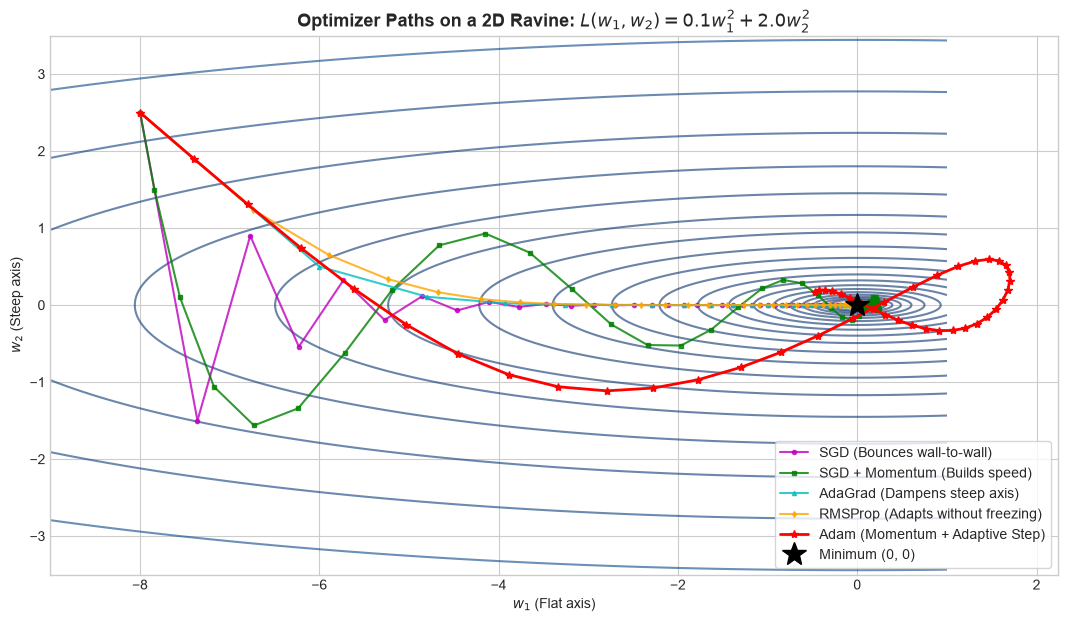

In [10]:
# Visualization: 2D Contour Map of all 5 Optimizers
w1_grid = np.linspace(-9, 1, 400)
w2_grid = np.linspace(-3.5, 3.5, 400)
W1, W2 = np.meshgrid(w1_grid, w2_grid)
Z = 0.1 * W1**2 + 2.0 * W2**2

plt.figure(figsize=(13, 7))
contours = plt.contour(W1, W2, Z, levels=np.logspace(-2, 2.5, 25), cmap='Blues_r', alpha=0.6)

# Plot paths
plt.plot(sgd_path[:, 0], sgd_path[:, 1], 'm-o', markersize=3, label='SGD (Bounces wall-to-wall)', alpha=0.8)
plt.plot(mom_path[:, 0], mom_path[:, 1], 'g-s', markersize=3, label='SGD + Momentum (Builds speed)', alpha=0.8)
plt.plot(ada_path[:, 0], ada_path[:, 1], 'c-^', markersize=3, label='AdaGrad (Dampens steep axis)', alpha=0.8)
plt.plot(rms_path[:, 0], rms_path[:, 1], 'orange', marker='d', markersize=3, label='RMSProp (Adapts without freezing)', alpha=0.8)
plt.plot(adam_path[:, 0], adam_path[:, 1], 'r-*', markersize=6, label='Adam (Momentum + Adaptive Step)', lw=2)

plt.plot(0, 0, 'k*', markersize=18, label='Minimum (0, 0)')
plt.title("Optimizer Paths on a 2D Ravine: $L(w_1, w_2) = 0.1 w_1^2 + 2.0 w_2^2$", fontsize=13, fontweight='bold')
plt.xlabel("$w_1$ (Flat axis)")
plt.ylabel("$w_2$ (Steep axis)")
plt.legend(loc='lower right', frameon=True)
plt.show()


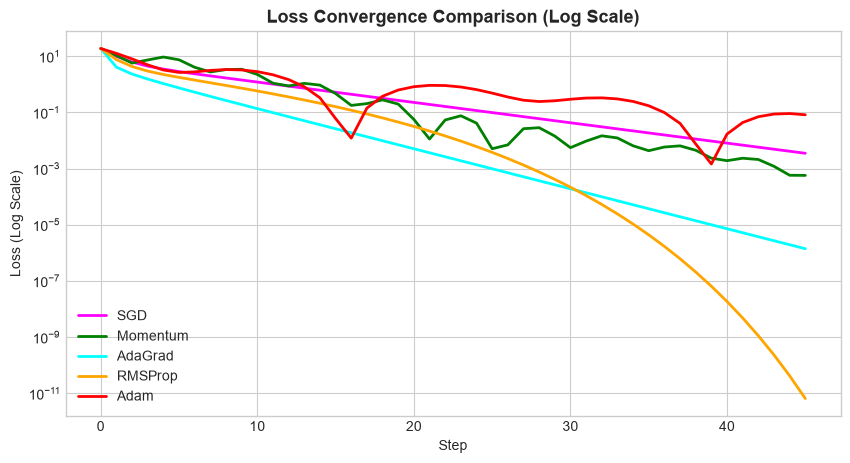

Final Loss after 45 steps:
SGD        : 0.00352439
Momentum   : 0.00057566
AdaGrad    : 0.00000141
RMSProp    : 0.00000000
Adam       : 0.08265380


In [11]:
# Loss Convergence Curve Comparison
paths = {
    'SGD': sgd_path,
    'Momentum': mom_path,
    'AdaGrad': ada_path,
    'RMSProp': rms_path,
    'Adam': adam_path
}
colors = {'SGD': 'magenta', 'Momentum': 'green', 'AdaGrad': 'cyan', 'RMSProp': 'orange', 'Adam': 'red'}

plt.figure(figsize=(10, 5))
for name, p in paths.items():
    losses = [ravine_loss(pt) for pt in p]
    plt.plot(losses, label=name, color=colors[name], lw=2)

plt.yscale('log')
plt.title("Loss Convergence Comparison (Log Scale)", fontsize=13, fontweight='bold')
plt.xlabel("Step")
plt.ylabel("Loss (Log Scale)")
plt.legend()
plt.show()

print("Final Loss after 45 steps:")
for name, p in paths.items():
    print(f"{name:10s} : {ravine_loss(p[-1]):.8f}")


---
## Part 5: Key Takeaways & Cheat Sheet 📋

| Optimizer | Simple Intuition | What It Tracks | Trade-Off (Pros vs. Cons) | Best Used For |
| :--- | :--- | :--- | :--- | :--- |
| **SGD** | Blindfolded single step using only current slope. | Current gradient only. | **+** Fast, low memory.<br>**−** Zig-zags in valleys; crawls on plateaus. | Simple baselines, massive datasets with tight memory. |
| **SGD + Momentum** | Heavy bowling ball building speed downhill ($10\times$ faster). | Past **gradients** (velocity). | **+** Rolls over plateaus; stops zig-zagging.<br>**−** Can overshoot the minimum. | **Computer Vision (CNNs / ResNets)** for strong generalization. |
| **AdaGrad** | Shrink step size on steep slopes, keep larger on flat ones. | **All** past **squared gradients**. | **+** Great for rare/sparse features.<br>**−** Learning rate shrinks to $0$ and freezes. | **Sparse data** (simple NLP / recommender systems); **not** deep nets. |
| **RMSProp** | AdaGrad with short-term memory (only recent slopes). | **Recent** squared gradients. | **+** Fixes AdaGrad's freezing issue.<br>**−** No directional momentum buildup. | **RNNs**, reinforcement learning, non-stationary tasks. |
| **Adam** | **Momentum + RMSProp** (heavy ball + smart step size). | Both past **gradients** & **squared gradients**. | **+** Fast, minimal tuning needed.<br>**−** Extra memory; can slightly overfit on CNNs. | **Default for Deep Learning** (MLPs, Transformers, LLMs). |

### Summary Rules of Thumb:
1. **Adam is your default:** For 90% of modern deep learning tasks (Transformers, MLPs, general NLP), start with **Adam** (learning rate $\eta = 0.001$).
2. **SGD with Momentum for Computer Vision:** When training CNNs or ResNets from scratch, tuned **SGD + Momentum** often achieves slightly better test set generalization than Adam.
3. **Never use AdaGrad on deep networks:** Because the accumulated squared gradients never decay, the effective learning rate monotonically drops until learning completely stalls.
